In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
print("All set:", pd.__version__)

Matplotlib is building the font cache; this may take a moment.


All set: 3.1.1


In [2]:
import os
print(os.listdir("data"))

['powerconsumption_datadictionary.csv', '.DS_Store', 'powerconsumption.csv']


In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv("data/powerconsumption.csv")
dd = pd.read_csv("data/powerconsumption_datadictionary.csv")

In [4]:
pd.set_option("display.max_colwidth", None)
dd

,Field,Description
0,Datetime,The date and time of the recording
1,Temperature,The Temperature in Celsius
2,Humidity,The concentration of water vapor in the air
3,WindSpeed,The speed of the wind in kilometers per hour
4,GeneralDiffuseFlows,The measurement of how much emissions gases diffuse into the broader atmosphere
5,DiffuseFlows,The measurement of how much emissions gases diffuse into the local atmosphere
6,PowerConsumption_Zone1,The power consumption in Kilowatt-Hours in Power Zone 1
7,PowerConsumption_Zone2,The power consumption in Kilowatt-Hours in Power Zone 2
8,PowerConsumption_Zone3,The power consumption in Kilowatt-Hours in Power Zone 3


In [5]:
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
df.info()
df.head()

Shape: (52416, 9)

Columns: ['Datetime', 'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']
<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 3.6 MB


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [6]:
print("Missing values per column:\n", df.isna().sum())
print("\nFully duplicated rows:", df.duplicated().sum())
print("Duplicate timestamps:", df["Datetime"].duplicated().sum())

Missing values per column:
 Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64

Fully duplicated rows: 0
Duplicate timestamps: 0


In [7]:
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
print("Unparseable dates:", df["Datetime"].isna().sum())
print(df["Datetime"].min(), "to", df["Datetime"].max())

Unparseable dates: 0
2017-01-01 00:00:00 to 2017-12-30 23:50:00


In [8]:
df = df.sort_values("Datetime").reset_index(drop=True)
gaps = df["Datetime"].diff().dropna()
print(gaps.value_counts().head(10))
print("Rows with a gap other than 10 min:", (gaps != pd.Timedelta(minutes=10)).sum())

Datetime
0 days 00:10:00    52415
Name: count, dtype: int64
Rows with a gap other than 10 min: 0


In [9]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Datetime,52416,2017-07-01 23:55:00,2017-01-01 00:00:00,2017-04-01 23:57:30,2017-07-01 23:55:00,2017-09-30 23:52:30,2017-12-30 23:50:00,NaN
Temperature,52416.0,18.810024,3.247,14.41,18.78,22.89,40.01,5.815476
Humidity,52416.0,68.259518,11.34,58.31,69.86,81.4,94.8,15.551177
WindSpeed,52416.0,1.959489,0.05,0.078,0.086,4.915,6.483,2.348862
GeneralDiffuseFlows,52416.0,182.696614,0.004,0.062,5.0355,319.6,1163.0,264.40096
DiffuseFlows,52416.0,75.028022,0.011,0.122,4.456,101.0,936.0,124.210949
PowerConsumption_Zone1,52416.0,32344.970564,13895.6962,26310.668692,32265.92034,37309.018185,52204.39512,7130.562564
PowerConsumption_Zone2,52416.0,21042.509082,8560.081466,16980.766032,20823.168405,24713.71752,37408.86076,5201.465892
PowerConsumption_Zone3,52416.0,17835.406218,5935.17407,13129.32663,16415.11747,21624.10042,47598.32636,6622.165099


In [10]:
print("Full duplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df["Datetime"].duplicated().sum())
print(df["Datetime"].min(), "to", df["Datetime"].max())
print("Unique days:", df["Datetime"].dt.date.nunique())
df.describe().T

Full duplicate rows: 0
Duplicate timestamps: 0
2017-01-01 00:00:00 to 2017-12-30 23:50:00
Unique days: 364


,count,mean,min,25%,50%,75%,max,std
Datetime,52416,2017-07-01 23:55:00,2017-01-01 00:00:00,2017-04-01 23:57:30,2017-07-01 23:55:00,2017-09-30 23:52:30,2017-12-30 23:50:00,NaN
Temperature,52416.0,18.810024,3.247,14.41,18.78,22.89,40.01,5.815476
Humidity,52416.0,68.259518,11.34,58.31,69.86,81.4,94.8,15.551177
WindSpeed,52416.0,1.959489,0.05,0.078,0.086,4.915,6.483,2.348862
GeneralDiffuseFlows,52416.0,182.696614,0.004,0.062,5.0355,319.6,1163.0,264.40096
DiffuseFlows,52416.0,75.028022,0.011,0.122,4.456,101.0,936.0,124.210949
PowerConsumption_Zone1,52416.0,32344.970564,13895.6962,26310.668692,32265.92034,37309.018185,52204.39512,7130.562564
PowerConsumption_Zone2,52416.0,21042.509082,8560.081466,16980.766032,20823.168405,24713.71752,37408.86076,5201.465892
PowerConsumption_Zone3,52416.0,17835.406218,5935.17407,13129.32663,16415.11747,21624.10042,47598.32636,6622.165099


In [11]:
df["Year"] = df["Datetime"].dt.year
df["Month"] = df["Datetime"].dt.month
df["Month_Name"] = df["Datetime"].dt.month_name()
df["Day"] = df["Datetime"].dt.day
df["Hour"] = df["Datetime"].dt.hour
df["DayOfWeek"] = df["Datetime"].dt.day_name()
df["DayOfWeek_Num"] = df["Datetime"].dt.dayofweek   # Monday = 0
df["Date"] = df["Datetime"].dt.date
df["IsWeekend"] = df["DayOfWeek_Num"] >= 5
df.head()

/var/folders/fc/53n5jkkx12b28cdbkj55mk8h0000gn/T/ipykernel_3648/1377696814.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["DayOfWeek_Num"] = df["Datetime"].dt.dayofweek   # Monday = 0


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Year,Month,Month_Name,Day,Hour,DayOfWeek,DayOfWeek_Num,Date,IsWeekend
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,2017,1,January,1,0,Sunday,6,2017-01-01,True
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,2017,1,January,1,0,Sunday,6,2017-01-01,True
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,2017,1,January,1,0,Sunday,6,2017-01-01,True
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,2017,1,January,1,0,Sunday,6,2017-01-01,True
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,2017,1,January,1,0,Sunday,6,2017-01-01,True


In [12]:
zones = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]
for z in zones:
    q1, q3 = df[z].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((df[z] < low) | (df[z] > high)).sum()
    print(f"{z}: bounds {low:,.0f} to {high:,.0f} | flagged: {n}")

PowerConsumption_Zone1: bounds 9,813 to 53,807 | flagged: 0
PowerConsumption_Zone2: bounds 5,381 to 36,313 | flagged: 7
PowerConsumption_Zone3: bounds 387 to 34,366 | flagged: 1191


In [13]:
cols = ["Datetime"] + zones + ["Temperature"]
df.nlargest(15, "PowerConsumption_Zone3")[cols]

,Datetime,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Temperature
29497,2017-07-24 20:10:00,51540.19934,35069.62025,47598.32636,29.13
29929,2017-07-27 20:10:00,51208.50498,34868.35443,47598.32636,27.93
29784,2017-07-26 20:00:00,50474.95017,34731.64557,47580.25105,34.30
29785,2017-07-26 20:10:00,50685.44850,34651.89873,47507.94979,33.94
29786,2017-07-26 20:20:00,50800.26578,34651.89873,47441.67364,33.58
29930,2017-07-27 20:20:00,51297.80731,34674.68354,47435.64854,27.74
29496,2017-07-24 20:00:00,50755.61462,35008.86076,47429.62343,29.39
29498,2017-07-24 20:20:00,51533.82060,34974.68354,47405.52301,28.84
29783,2017-07-26 19:50:00,49505.38206,34594.93671,47291.04603,34.87
29353,2017-07-23 20:10:00,47700.19934,31158.22785,47278.99582,28.02


In [14]:
df.groupby("Hour")[["GeneralDiffuseFlows", "DiffuseFlows"]].mean().round(1)

,GeneralDiffuseFlows,DiffuseFlows
Hour,,
0,0.1,0.1
1,0.1,0.1
2,0.1,0.1
3,0.1,0.1
4,0.1,0.1
5,0.1,0.1
6,5.5,4.7
7,47.0,39.2
8,145.5,109.3


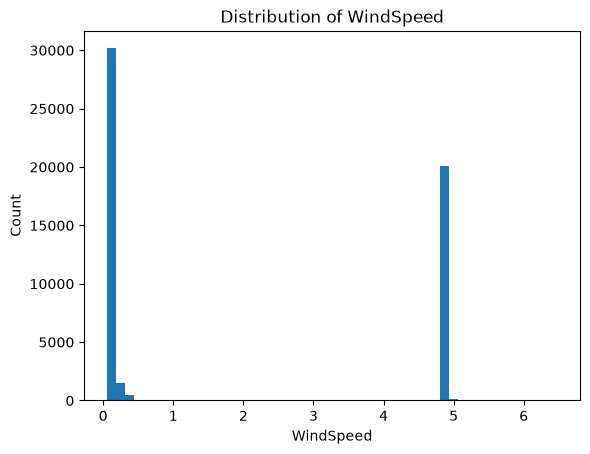

In [15]:
plt.hist(df["WindSpeed"], bins=50)
plt.title("Distribution of WindSpeed")
plt.xlabel("WindSpeed"); plt.ylabel("Count")
plt.show()

In [16]:
# Flag the Zone 3 outliers
q1, q3 = df["PowerConsumption_Zone3"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
z3_out = df[df["PowerConsumption_Zone3"] > upper]

print("By month:\n", z3_out["Month_Name"].value_counts())
print("\nBy hour:\n", z3_out["Hour"].value_counts().sort_index())
print("\nDistinct days affected:", z3_out["Date"].nunique())
print("Mean temperature of flagged rows:", round(z3_out["Temperature"].mean(), 1),
      "vs overall:", round(df["Temperature"].mean(), 1))

By month:
 Month_Name
July      760
August    431
Name: count, dtype: int64

By hour:
 Hour
0      17
12      3
13      5
18      9
19    222
20    317
21    299
22    217
23    102
Name: count, dtype: int64

Distinct days affected: 54
Mean temperature of flagged rows: 27.0 vs overall: 18.8


In [17]:
df["Zone3_HighFlag"] = df["PowerConsumption_Zone3"] > upper

In [18]:
df["WindSpeed_Level"] = np.where(df["WindSpeed"] > 2, "High (~4.9)", "Low (~0.1)")
print(df["WindSpeed_Level"].value_counts())

month_order = ["January","February","March","April","May","June","July",
               "August","September","October","November","December"]
print(pd.crosstab(df["Month_Name"], df["WindSpeed_Level"]).reindex(month_order))

WindSpeed_Level
Low (~0.1)     32103
High (~4.9)    20313
Name: count, dtype: int64
WindSpeed_Level  High (~4.9)  Low (~0.1)
Month_Name                              
January                  579        3885
February                 846        3186
March                    855        3609
April                    133        4187
May                     2053        2411
June                    1332        2988
July                    4205         259
August                  4116         348
September               2481        1839
October                 2496        1968
November                1063        3257
December                 154        4166


In [19]:
zones = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]
zone_summary = df[zones].agg(["mean", "median", "min", "max", "std"]).T.round(0)
zone_summary["CV (std/mean)"] = (zone_summary["std"] / zone_summary["mean"]).round(2)
zone_summary

,mean,median,min,max,std,CV (std/mean)
PowerConsumption_Zone1,32345.0,32266.0,13896.0,52204.0,7131.0,0.22
PowerConsumption_Zone2,21043.0,20823.0,8560.0,37409.0,5201.0,0.25
PowerConsumption_Zone3,17835.0,16415.0,5935.0,47598.0,6622.0,0.37


In [20]:
hourly = df.groupby("Hour")[zones].mean().round(0)
hourly

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,30217.0,19692.0,18657.0
1,27566.0,17765.0,16971.0
2,26293.0,16730.0,15981.0
3,25338.0,16053.0,15239.0
4,24634.0,15624.0,14671.0
5,23438.0,14975.0,13226.0
6,23204.0,14935.0,12052.0
7,24038.0,15719.0,11668.0
8,26583.0,17530.0,12794.0


In [21]:
dow_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
dow = df.groupby("DayOfWeek")[zones].mean().reindex(dow_order).round(0)
dow

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
DayOfWeek,,,
Monday,32615.0,21280.0,17809.0
Tuesday,32713.0,21519.0,17832.0
Wednesday,32872.0,21627.0,17851.0
Thursday,32842.0,21845.0,17844.0
Friday,32339.0,21461.0,17546.0
Saturday,32253.0,20586.0,18011.0
Sunday,30780.0,18979.0,17955.0


In [22]:
month_order = ["January","February","March","April","May","June","July",
               "August","September","October","November","December"]
monthly = df.groupby("Month_Name")[zones].mean().reindex(month_order).round(0)
monthly

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Month_Name,,,
January,31032.0,19394.0,17746.0
February,30986.0,18788.0,17335.0
March,31155.0,18458.0,16948.0
April,31170.0,17634.0,18593.0
May,32396.0,19977.0,17621.0
June,34606.0,20671.0,20431.0
July,35832.0,24148.0,28194.0
August,36435.0,24656.0,24649.0
September,33397.0,20180.0,14923.0


In [23]:
daily = df.groupby("Date")[zones].mean()
for z in zones:
    print(z, "| highest day:", daily[z].idxmax(), round(daily[z].max()),
          "| lowest day:", daily[z].idxmin(), round(daily[z].min()))

PowerConsumption_Zone1 | highest day: 2017-08-08 38733 | lowest day: 2017-01-15 26772
PowerConsumption_Zone2 | highest day: 2017-07-24 28355 | lowest day: 2017-04-02 14779
PowerConsumption_Zone3 | highest day: 2017-07-25 32700 | lowest day: 2017-12-01 10531


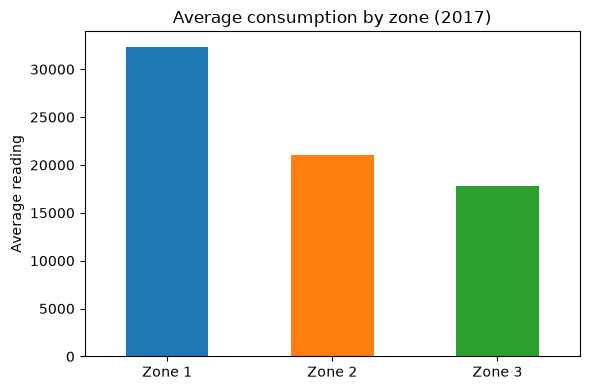

In [24]:
import os
os.makedirs("visuals", exist_ok=True)
labels = {"PowerConsumption_Zone1":"Zone 1","PowerConsumption_Zone2":"Zone 2","PowerConsumption_Zone3":"Zone 3"}

ax = df[zones].mean().rename(labels).plot(kind="bar", color=["#1f77b4","#ff7f0e","#2ca02c"], figsize=(6,4))
ax.set_title("Average consumption by zone (2017)")
ax.set_ylabel("Average reading")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visuals/avg_by_zone.png", dpi=150)
plt.show()

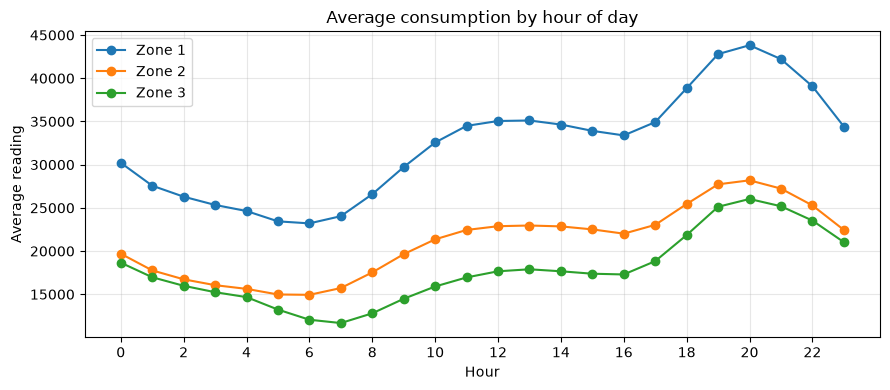

In [25]:
hourly.rename(columns=labels).plot(marker="o", figsize=(9,4))
plt.title("Average consumption by hour of day")
plt.xlabel("Hour"); plt.ylabel("Average reading")
plt.xticks(range(0,24,2)); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("visuals/hourly_pattern.png", dpi=150)
plt.show()

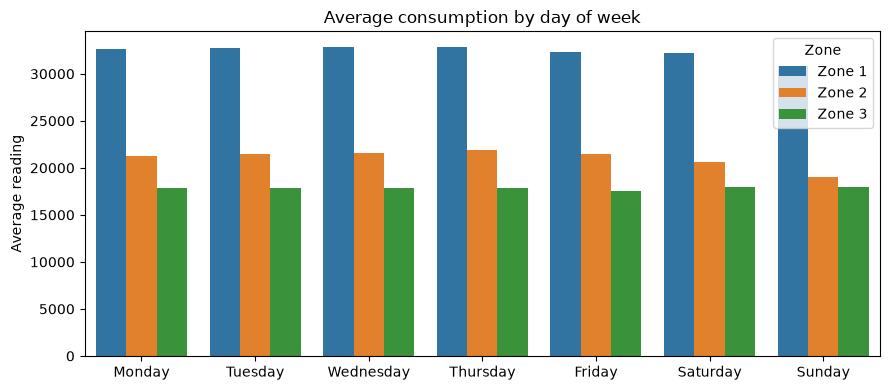

In [26]:
dow_long = dow.rename(columns=labels).reset_index().melt(id_vars="DayOfWeek", var_name="Zone", value_name="Avg")
plt.figure(figsize=(9,4))
sns.barplot(data=dow_long, x="DayOfWeek", y="Avg", hue="Zone", order=dow_order)
plt.title("Average consumption by day of week")
plt.xlabel(""); plt.ylabel("Average reading")
plt.tight_layout()
plt.savefig("visuals/day_of_week.png", dpi=150)
plt.show()

In [27]:
fig = px.line(monthly.rename(columns=labels).reset_index(), x="Month_Name", y=["Zone 1","Zone 2","Zone 3"],
              markers=True, title="Average consumption by month")
fig.update_layout(xaxis_title="", yaxis_title="Average reading", legend_title="Zone")
fig.write_html("visuals/monthly_pattern.html")
fig.show()

In [28]:
fig = px.line(daily.rename(columns=labels).reset_index(), x="Date", y=["Zone 1","Zone 2","Zone 3"],
              title="Daily average consumption over 2017")
fig.update_layout(xaxis_title="", yaxis_title="Daily average reading", legend_title="Zone")
fig.write_html("visuals/daily_trend.html")
fig.show()

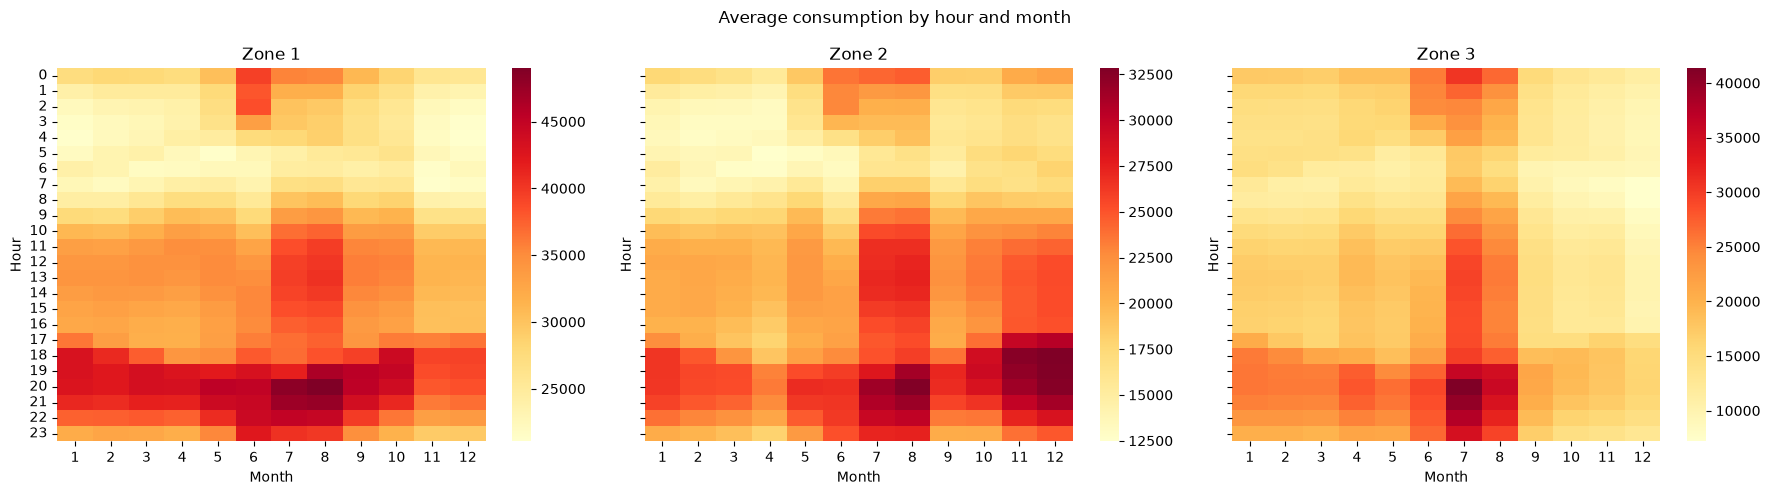

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18,5), sharey=True)
for ax, z in zip(axes, zones):
    pivot = df.pivot_table(index="Hour", columns="Month", values=z, aggfunc="mean")
    sns.heatmap(pivot, cmap="YlOrRd", ax=ax)
    ax.set_title(labels[z]); ax.set_xlabel("Month")
plt.suptitle("Average consumption by hour and month")
plt.tight_layout()
plt.savefig("visuals/heatmaps_by_zone.png", dpi=150)
plt.show()

In [30]:
print(df.groupby("WindSpeed_Level")[["Temperature"] + zones].mean().round(1))

                 Temperature  PowerConsumption_Zone1  PowerConsumption_Zone2  \
WindSpeed_Level                                                                
High (~4.9)             22.3                 33839.1                 22002.6   
Low (~0.1)              16.6                 31399.6                 20435.0   

                 PowerConsumption_Zone3  
WindSpeed_Level                          
High (~4.9)                     20162.9  
Low (~0.1)                      16362.7  


In [31]:
env = ["Temperature", "Humidity", "WindSpeed"]
pearson = df[env + zones].corr(method="pearson").loc[env, zones].round(2)
spearman = df[env + zones].corr(method="spearman").loc[env, zones].round(2)
print("Pearson:\n", pearson, "\n\nSpearman:\n", spearman)

Pearson:
              PowerConsumption_Zone1  PowerConsumption_Zone2  \
Temperature                    0.44                    0.38   
Humidity                      -0.29                   -0.29   
WindSpeed                      0.17                    0.15   

             PowerConsumption_Zone3  
Temperature                    0.49  
Humidity                      -0.23  
WindSpeed                      0.28   

Spearman:
              PowerConsumption_Zone1  PowerConsumption_Zone2  \
Temperature                    0.43                    0.38   
Humidity                      -0.30                   -0.31   
WindSpeed                      0.11                    0.09   

             PowerConsumption_Zone3  
Temperature                    0.44  
Humidity                      -0.21  
WindSpeed                      0.08  


In [32]:
env = ["Temperature", "Humidity", "WindSpeed"]
pearson = df[env + zones].corr(method="pearson").loc[env, zones].round(2)
spearman = df[env + zones].corr(method="spearman").loc[env, zones].round(2)
print("Pearson:\n", pearson, "\n\nSpearman:\n", spearman)

Pearson:
              PowerConsumption_Zone1  PowerConsumption_Zone2  \
Temperature                    0.44                    0.38   
Humidity                      -0.29                   -0.29   
WindSpeed                      0.17                    0.15   

             PowerConsumption_Zone3  
Temperature                    0.49  
Humidity                      -0.23  
WindSpeed                      0.28   

Spearman:
              PowerConsumption_Zone1  PowerConsumption_Zone2  \
Temperature                    0.43                    0.38   
Humidity                      -0.30                   -0.31   
WindSpeed                      0.11                    0.09   

             PowerConsumption_Zone3  
Temperature                    0.44  
Humidity                      -0.21  
WindSpeed                      0.08  


In [33]:
hourly_df = df.set_index("Datetime")[env + zones].resample("h").mean().reset_index()

for var in env:
    fig = px.scatter(
        hourly_df.melt(id_vars=["Datetime", var], value_vars=zones, var_name="Zone", value_name="Consumption"),
        x=var, y="Consumption", color="Zone", opacity=0.3,
        title=f"{var} vs consumption (hourly averages)")
    fig.write_html(f"visuals/scatter_{var.lower()}.html")
    fig.show()

          PowerConsumption_Zone1  PowerConsumption_Zone2  \
TempBand                                                   
(0, 10]                  25340.0                 17171.0   
(10, 15]                 29907.0                 19496.0   
(15, 20]                 31190.0                 20428.0   
(20, 25]                 34005.0                 21573.0   
(25, 30]                 37287.0                 24486.0   
(30, 45]                 39501.0                 27062.0   

          PowerConsumption_Zone3  
TempBand                          
(0, 10]                  13175.0  
(10, 15]                 15900.0  
(15, 20]                 15764.0  
(20, 25]                 18369.0  
(25, 30]                 24523.0  
(30, 45]                 28928.0  


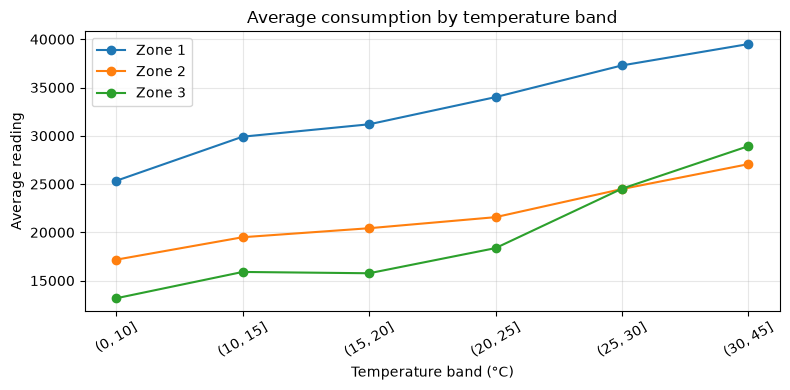

In [34]:
df["TempBand"] = pd.cut(df["Temperature"], bins=[0,10,15,20,25,30,45])
band = df.groupby("TempBand", observed=True)[zones].mean().round(0)
print(band)

band.rename(columns=labels).plot(marker="o", figsize=(8,4))
plt.title("Average consumption by temperature band")
plt.xlabel("Temperature band (°C)"); plt.ylabel("Average reading")
plt.xticks(range(len(band)), band.index.astype(str), rotation=30)
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("visuals/consumption_by_temp_band.png", dpi=150)
plt.show()

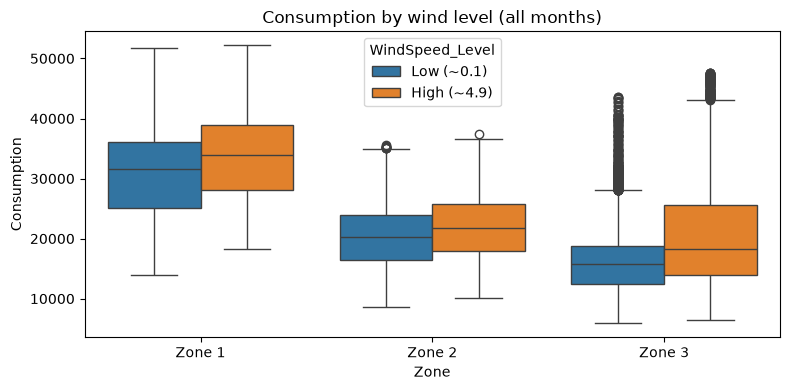

                 PowerConsumption_Zone1  PowerConsumption_Zone2  \
WindSpeed_Level                                                   
High (~4.9)                     35850.0                 24139.0   
Low (~0.1)                      35533.0                 24292.0   

                 PowerConsumption_Zone3  
WindSpeed_Level                          
High (~4.9)                     28195.0  
Low (~0.1)                      28176.0  


In [35]:
plt.figure(figsize=(8,4))
wind_long = df.melt(id_vars="WindSpeed_Level", value_vars=zones, var_name="Zone", value_name="Consumption")
wind_long["Zone"] = wind_long["Zone"].map(labels)
sns.boxplot(data=wind_long, x="Zone", y="Consumption", hue="WindSpeed_Level")
plt.title("Consumption by wind level (all months)")
plt.tight_layout()
plt.savefig("visuals/consumption_by_wind_level.png", dpi=150)
plt.show()

# Same comparison within July only, where both levels exist
july = df[df["Month"] == 7]
print(july.groupby("WindSpeed_Level")[zones].mean().round(0))

In [36]:
adj = df.copy()
for col in zones + env:
    adj[col] = adj[col] - adj.groupby("Hour")[col].transform("mean")

print("Spearman after removing the hour-of-day pattern:\n",
      adj[env + zones].corr(method="spearman").loc[env, zones].round(2))

Spearman after removing the hour-of-day pattern:
              PowerConsumption_Zone1  PowerConsumption_Zone2  \
Temperature                    0.53                    0.33   
Humidity                      -0.06                   -0.08   
WindSpeed                      0.28                    0.18   

             PowerConsumption_Zone3  
Temperature                    0.42  
Humidity                      -0.09  
WindSpeed                      0.19  


In [37]:
adj2 = df.copy()
for col in zones + env:
    adj2[col] = adj2[col] - adj2.groupby(["Month", "Hour"])[col].transform("mean")

print("Spearman after removing hour-of-day AND month effects:\n",
      adj2[env + zones].corr(method="spearman").loc[env, zones].round(2))

Spearman after removing hour-of-day AND month effects:
              PowerConsumption_Zone1  PowerConsumption_Zone2  \
Temperature                    0.05                    0.03   
Humidity                      -0.04                   -0.05   
WindSpeed                     -0.02                   -0.06   

             PowerConsumption_Zone3  
Temperature                    0.13  
Humidity                      -0.08  
WindSpeed                     -0.00  
